# Asystent Wodny – pipeline krok po kroku na prawdziwej działce

Notebook przechodzi przez **dokładnie te same funkcje backendu**, których używa API (`backend/app/*`), i pokazuje:

1. **Część A – pobieranie (API):** co pobieramy z którego źródła, jak wygląda surowa odpowiedź i po co nam to jest.
2. **Część B – obliczenia:** co liczymy z tych danych, jakim wzorem, jakie wartości wychodzą dla tej działki i co z nich wynika w raporcie.
3. **Część C – zalecenia:** kiedy i dlaczego uruchamia się każda reguła R1–R9 i jak wybieramy miejsce działania na mapie.

**Przykład:** działka **041005_5.0028.47/15** (gm. Szubin, woj. kujawsko‑pomorskie), **data analizy D = 15.07.2025**.
Wybrana, bo w deklaracji ARiMR 2025 prawie cała jest obsiana kukurydzą na ziarno, czyli uprawą z urzędowym progiem suszy IUNG.

Wykresy zapisują się do `notebooks/fig/` (używa ich schemat pipeline'u). Odpowiedzi źródeł trafiają do `backend/.cache`,
więc kolejne uruchomienie trwa kilka sekund.

> Uruchomienie: z katalogu głównego repo `python -m jupyter nbconvert --to notebook --execute --inplace notebooks/pipeline_dzialka.ipynb`
> albo otwórz w VS Code / Jupyter i uruchom wszystkie komórki. Do Sentinel Hub potrzebny jest `backend/.env` z `CDSE_CLIENT_ID/SECRET`;
> bez niego notebook bierze zdjęcia z Planetary Computer (bez konta).

In [1]:
import sys, json, math, asyncio
from pathlib import Path
from datetime import date, timedelta
from collections import Counter

import httpx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "backend"))

from app import sources, context, terrain, bdot, cdse, satellite, geo, config as C
from app.facts import (Meteo, Plan, bilans, ocena_kbw_teraz, sezon_kbw, scenariusze, okresy_roku, prog_iung,
                       s_cn, odplyw, horyzont, _shift)
from app.crops import UPRAWY, kc_dnia, w_oknie, z_arimr
from app.analysis import analizuj, _clms_rok
import matplotlib.dates as mdates
DM = mdates.DateFormatter('%d.%m')

ID = "041005_5.0028.47/15"
D = date(2025, 7, 15)

FIG = ROOT / "notebooks" / "fig"
FIG.mkdir(parents=True, exist_ok=True)
NIEB, ZIEL, POM, CZER, SZARY, TEKST = "#1f63b5", "#1e8a5a", "#e0622c", "#c2362f", "#8a8f87", "#1a1c19"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "figure.dpi": 100})

client = httpx.AsyncClient()

def pokaz(w):
    stan = "OK" if w.ok else f"BRAK – {w.powod}"
    print(f"[{w.zrodlo}] {stan} · {w.czas_ms} ms{' · z cache' if w.z_cache else ''}")

def zapisz(fig, nazwa):
    fig.savefig(FIG / f"{nazwa}.png", dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()

def mm(x, nd=0):
    return f"{x:,.{nd}f}".replace(",", " ").replace(".", ",")

---
# Część A – pobieranie danych (API)

Zasada: **jedno wejście** (identyfikator działki + data) → z geometrii działki liczymy punkt, prostokąt i bufor,
a potem **równolegle** pytamy ~10 publicznych usług. Każde pobranie zwraca obiekt `Wynik`: albo dane, albo jawny
powód braku (wtedy reguła, która potrzebuje tych danych, się nie uruchamia, a raport mówi, czego zabrakło).

## A1. ULDK (GUGiK) – granica działki

**Co pobieramy:** geometrię działki (WKT, EPSG:4326) + TERYT, gminę, obręb, numer.
**Endpoint:** `https://uldk.gugik.gov.pl/?request=GetParcelById&id={ID}&result=geom_wkt,…&srid=4326`
(albo `GetParcelByXY` dla kliknięcia na mapie, `GetParcelByIdOrNr` dla obręb + numer).
**Po co:** wszystko dalej jest liczone *dla tej geometrii*: centroid → zapytania punktowe (pogoda, SoilGrids, EDO),
prostokąt → wycinki rastrów (teren, satelita), punkty wewnątrz → odczyty gleby i upraw, TERYT → paczka BDOT10k powiatu.

In [2]:
params = {"request": "GetParcelById", "id": ID,
          "result": "geom_wkt,id,teryt,voivodeship,county,commune,region,parcel", "srid": "4326"}
r = await client.get(sources.ULDK, params=params, timeout=20)
print("Surowa odpowiedź (początek):\n", r.text[:220], "…\n")

wd = await sources.dzialka(client, ID)
pokaz(wd)
dz = wd.dane
rings = dz["rings"]
print(f"{dz['wojewodztwo']} / {dz['powiat']} / gm. {dz['gmina']} / obręb {dz['obreb']} / nr {dz['numer']}")
print(f"pow. {mm(dz['pow_ha'], 2)} ha · centroid {dz['lat']:.5f} N, {dz['lon']:.5f} E · wierzchołków: {len(rings[0])}")

Surowa odpowiedź (początek):
 0
SRID=4326;POLYGON((17.7588270193839 53.0462997435242,17.7579126590391 53.0448014579675,17.7583557290677 53.0447125837679,17.7576850028931 53.0435707451969,17.7581795998124 53.0436778818964,17.7595611150373 53.043865174 …

[ULDK GUGiK] OK · 0 ms · z cache
kujawsko-pomorskie / powiat nakielski / gm. Szubin - ob. wiejski / obręb Stanisławka / nr 47/15
pow. 10,06 ha · centroid 53.04475 N, 17.76191 E · wierzchołków: 16


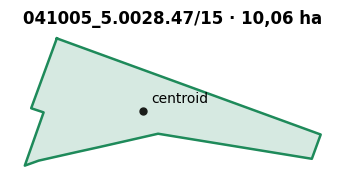

In [3]:
LAT0 = dz["lat"]
def obrys(ax, kolor=TEKST, lw=1.8, **kw):
    for rg in rings:
        xs, ys = zip(*(list(rg) + [rg[0]]))
        ax.plot(xs, ys, color=kolor, lw=lw, **kw)
    ax.set_aspect(1 / math.cos(math.radians(LAT0)))

def bez_osi(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

fig, ax = plt.subplots(figsize=(4.2, 3))
for rg in rings:
    xs, ys = zip(*rg); ax.fill(xs, ys, color=ZIEL, alpha=.18)
obrys(ax, ZIEL)
ax.plot(dz["lon"], dz["lat"], "o", color=TEKST, ms=5)
ax.annotate("centroid", (dz["lon"], dz["lat"]), xytext=(6, 6), textcoords="offset points", fontsize=10)
ax.set_title(f"{ID} · {mm(dz['pow_ha'], 2)} ha")
bez_osi(ax)
zapisz(fig, "a1_uldk")

## A2. Open‑Meteo Archive (ERA5‑Land) – pogoda dobowa z 31 lat

**Co pobieramy:** dla centroidu (siatka zaokrąglona do 0,05°) dobowo: opad, **ET0 FAO‑56** (parowanie wzorcowe),
Tmax, Tmin i wilgotność gleby w 3 warstwach – od 1.01.(D−31 lat) do D, **jednym zapytaniem**.
**Endpoint:** `https://archive-api.open-meteo.com/v1/archive?latitude=…&longitude=…&start_date=…&end_date=…&daily=precipitation_sum,et0_fao_evapotranspiration,…`
**Po co:**
- opad − ET0 → klimatyczny bilans wodny (KBW) i próg suszy IUNG (F1–F3), historia 10 sezonów (F5);
- opad i ET0 dzień po dniu → bilans wody w glebie FAO‑56 (F4) i scenariusze na przyszłość (F17–F21);
- 30 lat → „norma” opadu i parowania dla tych samych dni roku (F14), upał (F15), klimatologia zamiast prognozy dla dat archiwalnych (F11).

In [4]:
wm = await sources.meteo_archiwum(client, dz["lat"], dz["lon"], D)
pokaz(wm)
daily = wm.dane["daily"]
print("zmienne:", [k for k in daily if k != "time"])
print(f"dni: {len(daily['time'])} ({daily['time'][0]} → {daily['time'][-1]})")
m = Meteo.z_json(daily)
iD = m.idx[D]
print("\nostatnie 5 dni przed D:")
print(" data        opad  ET0   Tmax  wilg. 0–7 cm")
for i in range(iD - 4, iD + 1):
    print(f" {m.dni[i]}  {m.P[i]:4.1f}  {m.ET0[i]:4.2f}  {m.TMAX[i]:4.1f}  {daily['soil_moisture_0_to_7cm_mean'][i]}")

[Open‑Meteo (ERA5‑Land)] OK · 5 ms · z cache
zmienne: ['precipitation_sum', 'et0_fao_evapotranspiration', 'temperature_2m_max', 'temperature_2m_min', 'soil_moisture_0_to_7cm_mean', 'soil_moisture_7_to_28cm_mean', 'soil_moisture_28_to_100cm_mean']
dni: 11519 (1994-01-01 → 2025-07-15)

ostatnie 5 dni przed D:
 data        opad  ET0   Tmax  wilg. 0–7 cm
 2025-07-11   5.5  1.64  16.5  0.155
 2025-07-12   7.4  1.90  19.6  0.231
 2025-07-13   6.1  3.46  23.2  0.203
 2025-07-14   7.1  3.92  24.0  0.238
 2025-07-15   9.9  4.20  24.6  0.191


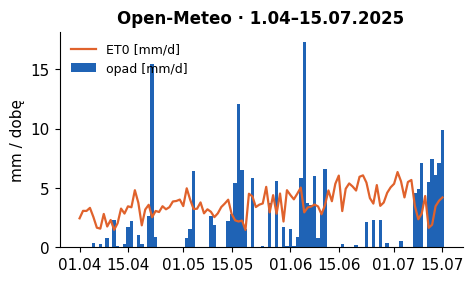

1.04–15.07.2025: opad 199 mm, ET0 386 mm


In [5]:
a, b = m.idx[date(2025, 4, 1)], iD
t = m.dni[a:b + 1]
fig, ax = plt.subplots(figsize=(5.2, 2.8))
ax.bar(t, m.P[a:b + 1], color=NIEB, width=1, label="opad [mm/d]")
ax.plot(t, m.ET0[a:b + 1], color=POM, lw=1.6, label="ET0 [mm/d]")
ax.set_ylabel("mm / dobę")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("Open‑Meteo · 1.04–15.07.2025")
ax.xaxis.set_major_formatter(DM)
zapisz(fig, "a2_meteo")
print(f"1.04–15.07.2025: opad {mm(m.P[a:b+1].sum())} mm, ET0 {mm(m.ET0[a:b+1].sum())} mm")

## A3. Open‑Meteo Forecast – prognoza 16 dni

**Co pobieramy:** opad i ET0 na 16 dni naprzód (`https://api.open-meteo.com/v1/forecast?…&forecast_days=16`).
**Po co:** pierwsze dni scenariuszy (F17) i „deszcz w 7 dni” (F11) – decyduje, czy podlewać teraz (R7), czy deszcz wystarczy (R7‑).
**Tylko gdy D = dziś.** Tu D = 15.07.2025, więc analiza **nie używa** prognozy – zastępuje ją średnią z 10 lat dla tych samych 7 dni.
Poniżej pokazujemy tylko, jak wygląda odpowiedź (prognoza od dzisiaj).

In [6]:
wp = await sources.meteo_prognoza(client, dz["lat"], dz["lon"])
pokaz(wp)
if wp.ok:
    dd = wp.dane["daily"]
    print("prognoza od", dd["time"][0], "· opad 7 dni:", mm(sum(x or 0 for x in dd["precipitation_sum"][:7]), 1), "mm",
          "· ET0 7 dni:", mm(sum(x or 0 for x in dd["et0_fao_evapotranspiration"][:7]), 1), "mm  (w tej analizie nieużywane)")

[Open‑Meteo (prognoza 16 dni)] OK · 1045 ms
prognoza od 2026-11-21 · opad 7 dni: 4,3 mm · ET0 7 dni: 2,1 mm  (w tej analizie nieużywane)


## A4. IUNG‑PIB – kategoria podatności gleby na suszę + pokrycie terenu

**Co pobieramy:** kod z warstwy `Susza:katgl_landuse2024` (WMS GetFeatureInfo) w **do 7 punktach wewnątrz działki** → dominanta.
Kody: 1–4 = kategorie I–IV (I = piaski, najbardziej podatne), 5 = gleby organiczne, 11 las, 12 woda, 13 zabudowa, 14 drogi.
**Endpoint:** `https://sgeo.iung.pl/geoserver/Susza/wms?REQUEST=GetFeatureInfo&LAYERS=Susza:katgl_landuse2024&…`
**Po co:** kategoria wybiera **wiersz progu suszy** (F2), **pojemność wodną gleby TAW** (F6b) i podatność na odpływ (CN);
kody ≥ 11 → raport „poza zakresem” (to nie grunt rolny), kod 5 → reguła R4 (nie odwadniać).

In [7]:
pts = geo.grid_points(rings, 4)[:7]
kody = await asyncio.gather(*[sources._iung_punkt(client, x, y) for x, y in pts])
for (x, y), k in zip(pts, kody):
    print(f"  punkt {y:.5f} N {x:.5f} E → kod {k}")
wi = await sources.iung_kategoria(client, rings)
pokaz(wi)
print(wi.dane)

  punkt 53.04475 N 17.76191 E → kod 1
  punkt 53.04412 N 17.75980 E → kod 1
  punkt 53.04466 N 17.75980 E → kod 1
  punkt 53.04521 N 17.75980 E → kod 1
  punkt 53.04575 N 17.75980 E → kod 1
  punkt 53.04466 N 17.76191 E → kod 1
  punkt 53.04521 N 17.76191 E → kod 1
[IUNG‑PIB – kategorie gleb] OK · 1 ms
{'kody': [1, 1, 1, 1, 1, 1, 1], 'kategoria': 1, 'udzial_organiczne': 0.0, 'nierolnicza': False, 'nierolnicza_kod': None}


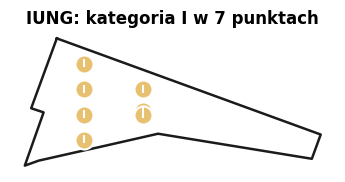

In [8]:
KOL_IUNG = {1: "#e8c170", 2: "#c9a46b", 3: "#9b8456", 4: "#6d5d3f", 5: "#3b4a3a"}
fig, ax = plt.subplots(figsize=(4.2, 3))
obrys(ax)
for (x, y), k in zip(pts, kody):
    ax.plot(x, y, "o", ms=13, color=KOL_IUNG.get(k, SZARY), mec="white", mew=1.5)
    ax.annotate(["", "I", "II", "III", "IV", "org."][k] if k and k <= 5 else str(k), (x, y), ha="center", va="center",
                fontsize=8, color="white", fontweight="bold")
ax.set_title(f"IUNG: kategoria {['', 'I', 'II', 'III', 'IV', 'org.'][wi.dane['kategoria']]} w {len(pts)} punktach")
bez_osi(ax)
zapisz(fig, "a4_iung")

## A5. ISRIC SoilGrids 250 m – skład gleby

**Co pobieramy:** piasek, ił, węgiel organiczny (SOC), wilgotność przy polowej pojemności (θFC, 33 kPa) i przy więdnięciu (θWP, 1500 kPa),
tylko dla 2 głębokości (5–15 i 30–60 cm), bo pełne zapytanie trwa 10–14 s.
**Endpoint:** `https://rest.isric.org/soilgrids/v2.0/properties/query?lon=…&lat=…&property=sand&property=clay&…`
**Po co:** **węgiel organiczny < 1,5%** uruchamia R5 (międzyplon/resztki), piasek i SOC trafiają do uzasadnienia „bo…”.
Do bilansu wody **nie** bierzemy TAW z SoilGrids (dla piasków bywa zawyżona) – bierzemy WOD z kategorii IUNG.

[ISRIC SoilGrids 250 m] OK · 0 ms · z cache
{'piasek': 71.15, 'il': 10.15, 'soc': 1.68, 'theta_fc': 0.323, 'theta_wp': 0.088, 'taw_1m': 235.0}


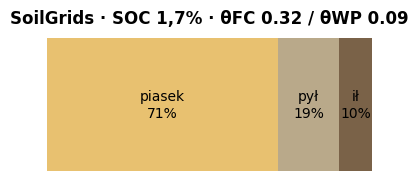

In [9]:
wsg = await context.soilgrids(client, dz["lon"], dz["lat"])
pokaz(wsg)
sg = wsg.dane
print({k: round(v, 3) for k, v in sg.items()})
fig, ax = plt.subplots(figsize=(4.2, 1.9))
pyl = max(0.0, 100 - sg["piasek"] - sg["il"])
lewo = 0
for nazwa, v, kol in [("piasek", sg["piasek"], "#e8c170"), ("pył", pyl, "#b9a98a"), ("ił", sg["il"], "#7a6248")]:
    ax.barh(0, v, left=lewo, color=kol)
    if v > 6: ax.text(lewo + v / 2, 0, f"{nazwa}\n{v:.0f}%", ha="center", va="center", fontsize=10)
    lewo += v
ax.set_xlim(0, 100); bez_osi(ax)
ax.set_title(f"SoilGrids · SOC {mm(sg['soc'], 1)}% · θFC {sg['theta_fc']:.2f} / θWP {sg['theta_wp']:.2f}")
zapisz(fig, "a5_soilgrids")

## A6. Progi suszy rolniczej IUNG (plik `dane/kbw_progi_iung.csv`)

**Co pobieramy:** tabelę progów klimatycznego bilansu wodnego (mm) z rozporządzenia MRiRW 2019 / susza.iung.pulawy.pl:
uprawa × kategoria gleby × 14 okresów 60‑dniowych (21.03–20.05, 1.04–31.05, … 1.08–30.09).
**Po co:** „susza rolnicza wg IUNG” = KBW z ostatniego pełnego okresu 60 dni **poniżej progu** dla tej uprawy i gleby (F2–F3),
oraz liczenie, w ilu z 10 sezonów próg był przekroczony (F5).

Kukurydza na ziarno – progi [mm] dla kategorii I–IV:
  kat. I   [None, None, None, -168.0, -161.0, -156.0, -153.0, -152.0, -153.0, -154.0, -156.0, -158.0, -161.0, -164.0]
  kat. II  [None, None, None, -200.0, -193.0, -188.0, -185.0, -184.0, -185.0, -186.0, -188.0, -190.0, -193.0, -196.0]
  kat. III [None, None, None, -236.0, -229.0, -224.0, -221.0, -220.0, -221.0, -222.0, -224.0, -226.0, -229.0, -232.0]
  kat. IV  [None, None, None, -271.0, -264.0, -259.0, -256.0, -255.0, -256.0, -257.0, -259.0, -261.0, -264.0, -267.0]


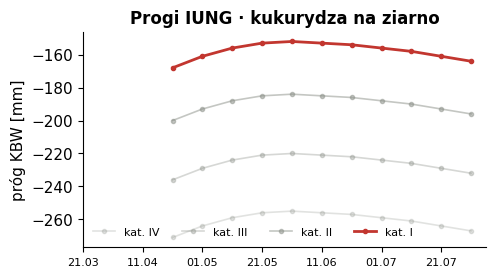

In [10]:
u_k = UPRAWY["kukurydza"]
okr = okresy_roku(2025)
print("Kukurydza na ziarno – progi [mm] dla kategorii I–IV:")
for kat_i in (1, 2, 3, 4):
    print(f"  kat. {['', 'I', 'II', 'III', 'IV'][kat_i]:3}", [prog_iung(u_k, kat_i, o[0]) for o in okr])
fig, ax = plt.subplots(figsize=(5.2, 2.8))
x = np.arange(len(okr))
for kat_i, alfa in ((4, .25), (3, .35), (2, .5), (1, 1)):
    y = [prog_iung(u_k, kat_i, o[0]) for o in okr]
    y = [np.nan if v is None else v for v in y]
    ax.plot(x, y, "-o", ms=3, color=CZER if kat_i == 1 else SZARY, alpha=alfa, lw=2 if kat_i == 1 else 1.2,
            label=f"kat. {['', 'I', 'II', 'III', 'IV'][kat_i]}")
ax.set_xticks(x[::2], [o[1][:5] for o in okr][::2], rotation=0, fontsize=8)
ax.set_ylabel("próg KBW [mm]")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="lower left")
ax.set_title("Progi IUNG · kukurydza na ziarno")
zapisz(fig, "a6_progi")

## A7. ARiMR GSA – deklaracje upraw (WFS, 2025–2026)

**Co pobieramy:** pola z wniosków o dopłaty przecinające prostokąt działki: `roslina`, `grupa_roslin`, `pow`.
**Endpoint:** `https://geoportal-w2.arimr.gov.pl/geoserver/gsa_public/uprawy_2025/wfs?REQUEST=GetFeature&TYPENAMES=gsa_public:uprawy_rolne_2025&BBOX=…`
**Po co:** **F0 – uprawa** decyduje o wszystkim dalej: który wiersz progów IUNG, współczynniki Kc (ile woda paruje w każdej fazie),
p (kiedy zaczyna się stres), głębokość korzeni, okno wrażliwości. W UI to tylko **podpowiedź** – rolnik może ją zmienić.
Udział liczymy na siatce punktów wewnątrz działki (14×14).

In [11]:
wa = await sources.arimr_uprawa(client, rings, 2025)
pokaz(wa)
print(wa.dane)
print("→ klucz uprawy w aplikacji:", z_arimr(wa.dane["roslina"]))

[ARiMR – deklaracje upraw 2025] OK · 0 ms · z cache
{'roslina': 'kukurydza na ziarno', 'grupa': 'pastewne', 'udzial': 0.9716981132075472, 'inne': ['pszenica zwyczajna jara', 'pszenżyto jare']}
→ klucz uprawy w aplikacji: kukurydza


## A8. Copernicus CLMS Crop Types 2017–2024 (CDSE) – uprawy w poprzednich latach

**Co pobieramy:** obrazek 2,5 × 2,5 km mapy typów upraw (10 m) z publicznej usługi podglądu CDSE dla każdego roku 2017–2024;
kolor piksela → klasa uprawy wg oficjalnej palety; dominanta pikseli w działce.
**Po co:** historię suszy (F5) liczymy **dla uprawy, która w danym roku rosła** (F0h) – próg dla pszenicy i kukurydzy jest inny.
Bez tej mapy przyjmujemy bieżącą uprawę dla każdego roku (raport to zaznacza).

In [12]:
wcl = await cdse.uprawy_clms(client, rings)
pokaz(wcl)
uprawy_lat = {}
for rok in sorted(wcl.dane or {}):
    c = wcl.dane[rok]
    uprawy_lat[int(rok)] = c["nazwa"]
    print(f"  {rok}: {c['nazwa']:28} ({100 * c['udzial']:.0f}% pikseli działki)")
uprawy_lat[2025] = wa.dane["roslina"] + " (ARiMR)"

[CLMS Crop Types 2017–2024 (CDSE)] OK · 0 ms · z cache
  2017: inne zboża                   (95% pikseli działki)
  2018: inne zboża                   (42% pikseli działki)
  2019: kukurydza                    (39% pikseli działki)
  2020: kukurydza                    (30% pikseli działki)
  2021: kukurydza                    (59% pikseli działki)
  2022: kukurydza                    (55% pikseli działki)
  2023: kukurydza                    (56% pikseli działki)
  2024: jęczmień                     (51% pikseli działki)


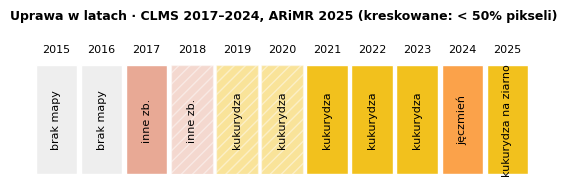

In [13]:
KOL_UPR = {"kukurydza": "#f2c11d", "pszenica": "#ee6e32", "jęczmień": "#fba24a", "inne zboża": "#e8a995",
           "rzepak": "#e377c2", "ziemniak": "#c98c43", "burak cukrowy": "#9c5b0c", "poza gruntami ornymi": "#cfd8c9"}
udz = {int(r_): c["udzial"] for r_, c in (wcl.dane or {}).items()}
lata_x = list(range(2015, 2026))
fig, ax = plt.subplots(figsize=(6.4, 1.9))
for i, y in enumerate(lata_x):
    n = uprawy_lat.get(y)
    kol = next((v for k, v in KOL_UPR.items() if n and n.startswith(k)), "#eeeeee" if not n else "#9fc5a8")
    niepewne = y in udz and udz[y] < 0.5
    ax.add_patch(plt.Rectangle((i, 0), .92, 1, facecolor=kol, alpha=.45 if niepewne else 1,
                               hatch="///" if niepewne else None, edgecolor="white"))
    ax.text(i + .46, 1.12, str(y), ha="center", fontsize=8)
    lab = "brak mapy" if not n else n.replace(" (ARiMR)", "").replace("inne zboża", "inne zb.")
    ax.text(i + .46, .5, lab, ha="center", va="center", fontsize=8, rotation=90)
ax.set_xlim(0, len(lata_x)); ax.set_ylim(0, 1.35); bez_osi(ax)
ax.set_title("Uprawa w latach · CLMS 2017–2024, ARiMR 2025 (kreskowane: < 50% pikseli)", fontsize=9)
zapisz(fig, "a8_uprawy")

## A9. Copernicus DEM 30 m – model terenu

**Co pobieramy:** wycinek kafla COG `cop-dem-glo-30` (katalog STAC Earth Search) – działka + bufor 400 m, czytany przez HTTP Range,
bez pobierania całego kafla. Dokładny **NMT 1 m z GUGiK** (WCS) odpowiada 60–117 s, więc pobiera się w tle i podmienia przy kolejnym raporcie.
**Po co:** spadki (F7), kierunki i akumulacja spływu D8 → **miejsce, którym woda ucieka z pola** (F7b), zagłębienia bezodpływowe (F8).

[Copernicus DEM 30 m] OK · 3899 ms
siatka 54×36 komórek, wysokość 68.3–109.7 m n.p.m.


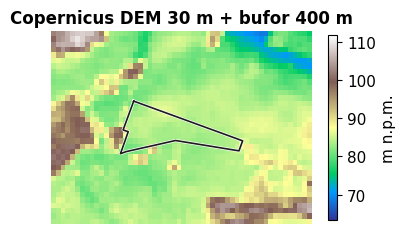

In [14]:
wdem = await terrain.pobierz_dem(client, rings)
pokaz(wdem)
Z, TR = wdem.dane["z"], wdem.dane["tr"]
h, w = Z.shape
EXT = [TR.c, TR.c + TR.a * w, TR.f + TR.e * h, TR.f]
print(f"siatka {w}×{h} komórek, wysokość {np.nanmin(Z):.1f}–{np.nanmax(Z):.1f} m n.p.m.")
fig, ax = plt.subplots(figsize=(4.2, 3))
im = ax.imshow(Z, extent=EXT, cmap="terrain", vmin=np.nanmin(Z) - 5, vmax=np.nanmax(Z) + 2)
obrys(ax, "white", 2.2); obrys(ax, TEKST, 1.2)
plt.colorbar(im, ax=ax, shrink=.8, label="m n.p.m.")
ax.set_title("Copernicus DEM 30 m + bufor 400 m"); bez_osi(ax)
zapisz(fig, "a9_dem")

## A10. BDOT10k – rowy, rzeki, kanały, zbiorniki

**Co pobieramy:** z paczki GML powiatu (~50 MB) przez **HTTP Range** tylko 4 pliki: `OT_SWRM_L` (rowy melioracyjne), `OT_SWRS_L` (rzeki),
`OT_SWKN_L` (kanały), `OT_PTWP_A` (wody powierzchniowe) – ok. 2 MB, cache per powiat.
**Endpoint:** `https://opendata.geoportal.gov.pl/bdot10k/schemat2021/{woj}/{powiat}_GML.zip`
**Po co:** odległość od granicy działki do najbliższego rowu (F9) → przyczyna C5 („rów odprowadza wodę”) i zalecenie **R1 – zastawka na rowie**.

In [15]:
wh = await bdot.hydrografia(rings, dz["teryt"] or dz["id"])
pokaz(wh)
hyd = wh.dane
for k, v in sorted(hyd["najblizsze"].items(), key=lambda kv: kv[1]["dist_m"]):
    print(f"  {v['typ']:22} {mm(v['dist_m'])} m od granicy {('„' + v['nazwa'] + '”') if v['nazwa'] else ''}")

[BDOT10k – hydrografia] OK · 529 ms
  rów melioracyjny       3 m od granicy 
  wody powierzchniowe    183 m od granicy 
  rzeka / strumień       267 m od granicy 


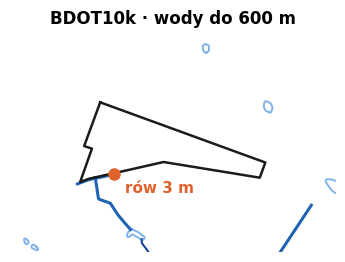

In [16]:
KOL_H = {"SWRM_L": NIEB, "SWRS_L": "#0b3d91", "SWKN_L": "#4b8fe0", "PTWP_A": "#7fb3ea"}
fig, ax = plt.subplots(figsize=(4.2, 3))
x0, y0, x1, y1 = geo.bbox(rings)
pad = 0.004
for l in hyd["linie"]:
    c = np.array(l["c"])
    ax.plot(c[:, 0], c[:, 1], color=KOL_H[l["typ"]], lw=2.2 if l["typ"] == "SWRM_L" else 1.4)
obrys(ax)
rw = hyd["najblizsze"].get("SWRM_L")
if rw:
    ax.plot(rw["lon"], rw["lat"], "o", color=POM, ms=8)
    ax.annotate(f"rów {mm(rw['dist_m'])} m", (rw["lon"], rw["lat"]), xytext=(8, -14), textcoords="offset points",
                color=POM, fontweight="bold")
ax.set_xlim(x0 - pad, x1 + pad); ax.set_ylim(y0 - pad * .6, y1 + pad * .6)
ax.set_title("BDOT10k · wody do 600 m"); bez_osi(ax)
zapisz(fig, "a10_bdot")

## A11. Sentinel‑2 L2A – wilgotność roślin (NDMI)

**Co pobieramy:** pasma B8A (bliska podczerwień) i B11 (krótkofalowa podczerwień, 20 m) + maskę chmur SCL tylko dla okna działki.
Źródło główne: **Sentinel Hub Process API (CDSE)** – kompozyt najmniej zachmurzonych przelotów z ostatnich 20 dni (≤ D);
zapas: **Planetary Computer** (STAC, bez konta) i **Landsat** dla lat < 2016.
Te same 20 dni pobieramy też z **poprzednich lat** (2016+) – to tło do porównania.
**Po co:** NDMI = (B8A − B11)/(B8A + B11) mówi, ile wody jest w liściach. Ale „0,15” nic nie znaczy samo w sobie –
liczy się, czy to **mniej niż zwykle w tych samych tygodniach** (z‑score, krok B8) → najsuchsza strefa działki (F10), tam kierujemy nawadnianie.

Sentinel Hub: kompozyt 2025-06-26 – 2025-07-15, siatka 37×17 pikseli 20 m, czystych w działce 250 z 250; NDMI mediana 0.152


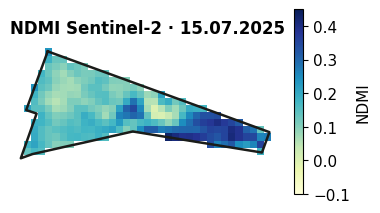

In [17]:
okno_sat = (D - timedelta(days=25), D)        # uprawa w wegetacji → ostatnie 25 dni
raw = await cdse.ndmi_sh(client, rings, D - timedelta(days=19), D)
if raw is not None:
    nd = np.where(raw["inside"] & raw["czyste"], raw["ndmi"], np.nan)
    print(f"Sentinel Hub: kompozyt {D - timedelta(days=19)} – {D}, siatka {nd.shape[1]}×{nd.shape[0]} pikseli 20 m, "
          f"czystych w działce {int(np.isfinite(nd).sum())} z {int(raw['inside'].sum())}; NDMI mediana {np.nanmedian(nd):.3f}")
    fig, ax = plt.subplots(figsize=(4.2, 3))
    pc = ax.pcolormesh(raw["lon"], raw["lat"], nd, cmap="YlGnBu", vmin=-0.1, vmax=0.45, shading="auto")
    obrys(ax); plt.colorbar(pc, ax=ax, shrink=.8, label="NDMI")
    ax.set_title(f"NDMI Sentinel‑2 · {D:%d.%m.%Y}"); bez_osi(ax)
    zapisz(fig, "a11_ndmi")
else:
    print("Brak dostępu do Sentinel Hub (backend/.env) – w kroku B8 użyjemy Planetary Computer.")

## A12. Europejskie Obserwatorium Suszy (EDO) – CDI

**Co pobieramy:** obrazek 9×9 pikseli warstwy `cdiad` (Combined Drought Indicator) wokół działki dla dekady ≤ D (WMS GetMap z `TIME`);
WMS nie ma GetFeatureInfo, więc klasę odczytujemy z koloru środkowego piksela: obserwacja / ostrzeżenie / alarm.
**Po co:** niezależne „drugie zdanie” w skali ~5 km – **czwarty sygnał pewności** diagnozy. Nie uruchamia żadnej reguły.

In [18]:
wedo = await context.edo_cdi(client, dz["lon"], dz["lat"], D)
pokaz(wedo)
print(wedo.dane)

[EDO – Combined Drought Indicator] OK · 0 ms · z cache
{'klasa': 'brak suszy', 'opis': 'wskaźniki w normie', 'dekada': '2025-07-11'}


## A13. Hydrologia – zlewnia (MPHP10k, Wody Polskie) i rzeki (IMGW‑PIB)

- **MPHP10k** (WMS `GetFeatureInfo`, warstwa `HY.PhysicalWaters.Catchments`): w jakiej zlewni leży działka → R1 pisze, skąd spływa woda do rowu,
  a przy zlewni większej niż ⚙️ 10 km² kieruje rolnika do zarządcy cieku zamiast budować zastawkę samemu.
- **IMGW‑PIB** (`/api/data/hydro/`, `/api/data/warningshydro`): najbliższy wodowskaz i ostrzeżenia o suszy hydrologicznej dla województwa.
  Ostrzeżenie zmienia R7/R8 („nie licz na pobór z cieku”) i podnosi retencję do „pilne”. **Dane są tylko bieżące** – dla dat archiwalnych
  raport mówi to wprost.

In [19]:
from app import hydro
wzl = await hydro.zlewnia(client, dz["lon"], dz["lat"])
pokaz(wzl)
print("backend bierze:", wzl.dane)

# Warstwa ma zlewnie zagnieżdżone (dorzecze → zlewnia elementarna). Ta sama usługa z FEATURE_COUNT=20:
d_ = 0.01
r_ = await client.get(hydro.MPHP_WMS, params={
    "SERVICE": "WMS", "VERSION": "1.3.0", "REQUEST": "GetFeatureInfo", "LAYERS": "HY.PhysicalWaters.Catchments",
    "QUERY_LAYERS": "HY.PhysicalWaters.Catchments", "CRS": "EPSG:4326", "STYLES": "", "INFO_FORMAT": "application/json",
    "BBOX": f"{dz['lat'] - d_:.5f},{dz['lon'] - d_:.5f},{dz['lat'] + d_:.5f},{dz['lon'] + d_:.5f}",
    "WIDTH": 101, "HEIGHT": 101, "I": 50, "J": 50, "FEATURE_COUNT": 20}, timeout=30)
for f in r_.json().get("features", []):
    z_ = hydro.zlewnia_z_json({"features": [f]})
    print(f"  {z_['pow_km2']:>12,.1f} km²  {z_['nazwa']}".replace(",", " "))
print("→ pierwsza zwrócona to całe dorzecze; zlewnią najbliższą rowowi jest najmniejsza z listy (do poprawki w hydro.zlewnia)")

print(f"\nIMGW (wodowskazy, ostrzeżenia): analiza na dziś? {hydro.biezace(D, date.today())} – dla D = {D} nie pytamy (dane tylko bieżące)")

[MPHP10k – zlewnie (Wody Polskie)] OK · 3 ms · z cache
backend bierze: {'nazwa': 'Odra', 'id': '6000', 'pow_km2': 118394.2916575044}


     118 394.3 km²  Odra
          32.3 km²  Noteć od Gąsawki do dopł. spod Niedźwiad (l)
→ pierwsza zwrócona to całe dorzecze; zlewnią najbliższą rowowi jest najmniejsza z listy (do poprawki w hydro.zlewnia)

IMGW (wodowskazy, ostrzeżenia): analiza na dziś? False – dla D = 2025-07-15 nie pytamy (dane tylko bieżące)


---
# Część B – obliczenia: co liczymy, dlaczego i co to daje

Najpierw uruchamiamy **całą analizę z backendu** (to samo, co robi `POST /api/raport`), a potem rozkładamy ją na kroki
i każdy krok liczymy ręcznie tymi samymi funkcjami – na końcu każdego kroku sprawdzamy zgodność z wynikiem backendu.

```
DANE (A1–A12) → FAKTY F0–F21 → DIAGNOZA (stan + przyczyny C1–C6) → REGUŁY R1–R9 → RAPORT
```

In [20]:
out = await analizuj(ID, None, None, D, None)
F = out["fakty"]
print("status:", out["status"]["label"], "–", out["status"]["head"])
print("uprawa:", out["uprawa"])
print("czas analizy:", out["czas_s"], "s")

status: Susza – Kukurydza już cierpi — zapas wody poniżej progu stresu
uprawa: {'key': 'kukurydza', 'nazwa': 'Kukurydza', 'zrodlo': 'deklaracja ARiMR 2025: kukurydza na ziarno', 'okno': 'lipiec–sierpień'}
czas analizy: 1.3 s


## B1. Wejścia modelu: uprawa (F0), gleba (F6), pojemność wodna (F6b), CN

- **Uprawa** z ARiMR → parametry FAO‑56: Kc (ini/mid/end), długości faz, **p** (jaki ułamek wody dostępnej roślina zużyje bez stresu),
  głębokość korzeni, okno wrażliwości (kukurydza: lipiec–sierpień, wiechowanie i kwitnienie).
- **TAW** (woda dostępna w strefie korzeni, mm) = WOD z kategorii IUNG (I: 110, II: 150, III: 185, IV: 220 mm/m) × głębokość korzeni.
  To „wielkość zbiornika”: na piasku kat. I mieści się dwa razy mniej wody niż na glebie kat. IV.
- **CN** (Curve Number) – ile deszczu z ulewy spływa po powierzchni zamiast wsiąkać; zależy od gleby.

In [21]:
u = UPRAWY[z_arimr(wa.dane["roslina"])]
kat = wi.dane["kategoria"]
TAW = C.WOD_MM[kat] * min(u.zr, 1.0)
CN = C.CN_02[kat]
RAW = u.p * TAW
print(f"uprawa: {u.nazwa} · Kc {u.kc} · fazy {u.fazy} dni od {u.start[1]}.{u.start[0]:02d} · p = {u.p} · korzenie {u.zr} m")
print(f"okno wrażliwości: {u.okno_opis} ({u.faza_krytyczna})")
print(f"gleba kat. {kat} → TAW = {C.WOD_MM[kat]:.0f} mm/m × {min(u.zr, 1.0)} m = {TAW:.0f} mm · RAW = p·TAW = {RAW:.1f} mm · CN = {CN}")
print("zgodne z backendem:", TAW == F["TAW"] and kat == F["kat"])

# uprawa w każdym roku – ta sama reguła co backend (L1, L2): rok D – deklaracja ARiMR; wcześniej – mapa upraw Copernicus
# (≥ 50% pikseli działki). ARiMR za D−1 (2024) nie ma usługi WFS, więc 2024 bierzemy z mapy Copernicus.
def uprawa_roku(y):
    if y == D.year:
        return u, "ARiMR"
    c_ = _clms_rok(wcl, y)
    return (UPRAWY[c_["key"]], "Copernicus") if c_ else (None, "nieznana – przyjęto bieżącą")
print("uprawa w latach:", ", ".join(f"{y}: {(uprawa_roku(y)[0].nazwa.lower() if uprawa_roku(y)[0] else '?')}" for y in range(2015, 2026)))

uprawa: Kukurydza · Kc (0.3, 1.2, 0.5) · fazy (30, 40, 50, 40) dni od 25.04 · p = 0.55 · korzenie 1.0 m
okno wrażliwości: lipiec–sierpień (wiechowanie i kwitnienie)
gleba kat. 1 → TAW = 110 mm/m × 1.0 m = 110 mm · RAW = p·TAW = 60.5 mm · CN = 67
zgodne z backendem: True
uprawa w latach: 2015: ?, 2016: ?, 2017: zboża ozime, 2018: ?, 2019: ?, 2020: ?, 2021: kukurydza, 2022: kukurydza, 2023: kukurydza, 2024: zboża jare, 2025: kukurydza


## B2. F1–F3: klimatyczny bilans wodny (KBW) i kryterium suszy IUNG

**Wzór:** KBW = Σ opad − Σ ET0 w **ostatnim pełnym okresie 60‑dniowym** kończącym się ≤ D. **Susza (F3)**, gdy KBW < próg (A6).
**Co daje:** urzędowa ocena „czy jest susza rolnicza” – ta sama metoda, której używa państwowy system monitoringu suszy (SMSR).
W raporcie to uzasadnienie pod nagłówkiem i jeden z 4 sygnałów pewności.

{'dostepny': True, 'niepelny': False, 'okres': '11.05–10.07.2025', 'kbw': -127.3, 'prog': -156.0, 'susza': False, 'P': 121.3, 'ET0': 248.6}


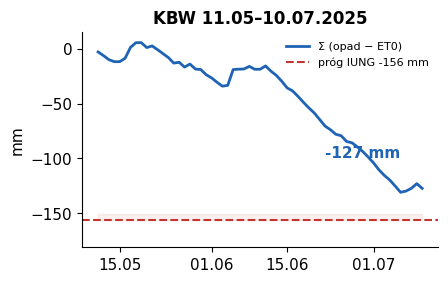

susza wg IUNG: NIE | zgodne z backendem: True


In [22]:
kbw = ocena_kbw_teraz(m, u, kat, D)
print({k: (round(v, 1) if isinstance(v, float) else v) for k, v in kbw.items()})
i_okr = next(o for o in okresy_roku(2025) if f"{o[2]:%d.%m}–{o[3]:%d.%m.%Y}" == kbw["okres"])
a, b = m.idx[i_okr[2]], m.idx[i_okr[3]]
cum = np.cumsum(m.P[a:b + 1] - m.ET0[a:b + 1])
fig, ax = plt.subplots(figsize=(4.6, 2.8))
ax.plot(m.dni[a:b + 1], cum, color=NIEB, lw=2, label="Σ (opad − ET0)")
ax.axhline(kbw["prog"], color=CZER, ls="--", lw=1.5, label=f"próg IUNG {kbw['prog']:.0f} mm")
ax.fill_between(m.dni[a:b + 1], kbw["prog"], cum.min() - 20, color=CZER, alpha=.07)
ax.annotate(f"{kbw['kbw']:.0f} mm", (m.dni[b], cum[-1]), xytext=(-70, 22), textcoords="offset points", color=NIEB, fontweight="bold")
ax.set_ylabel("mm"); ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set_ylim(kbw["prog"] - 25, max(15, cum.max() + 10))
ax.set_title(f"KBW {kbw['okres']}"); ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 15])); ax.xaxis.set_major_formatter(DM)
zapisz(fig, "b2_kbw")
print("susza wg IUNG:", "TAK" if kbw["susza"] else "NIE", "| zgodne z backendem:", round(kbw["kbw"], 1) == round(F["F1"]["kbw"], 1))

## B3. F4: zapas wody w glebie – dobowy bilans FAO‑56

**Wzór (FAO‑56, rozdz. 8), dzień po dniu od początku archiwum (gleba pełna na starcie):**

- odpływ z ulewy Q z metody SCS‑CN (λ = 0,05),
- `Dr = Dr − (opad − Q) + ETc`, gdzie **ETc = Ks · Kc(faza) · ET0**, ograniczone do [0, TAW],
- **Ks** = 1, dopóki Dr ≤ RAW; potem maleje liniowo do 0 (roślina zamyka aparaty szparkowe = **stres**),
- **zapas F4 = 1 − Dr/TAW**, **próg stresu F4p = 1 − p** (kukurydza: 45%).

**Co daje:** odpowiedź na pytanie rolnika „ile wody ma teraz moje pole” w %, z progiem, poniżej którego roślina traci plon.
Ten sam model to silnik scenariuszy (B9) i efektów działań (R3, R5, R7, R8).

Dr = 65.2 mm z 110 mm → zapas F4 = 41% · próg stresu F4p = 45% · Kc dziś 1.20 (pełnia)
zgodne z backendem: True


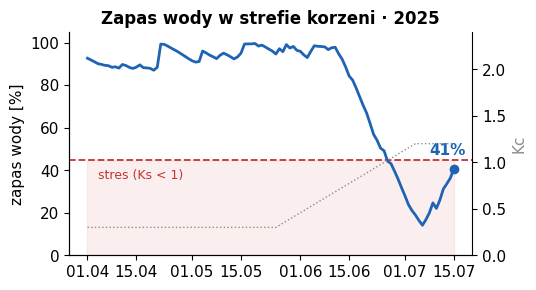

In [23]:
# w każdym roku Kc, p i korzenie uprawy, która wtedy rosła (lata nieznane → bieżąca uprawa)
ciag = bilans(m.P[:iD + 1], m.ET0[:iD + 1], m.dni[:iD + 1], u, TAW, CN, u_roku=lambda y: uprawa_roku(y)[0] or u)
Dr = float(ciag["Dr"][-1])
F4, F4p = 1 - Dr / TAW, 1 - u.p
kc_d, faza = kc_dnia(u, D, C.KC_POZA)
print(f"Dr = {Dr:.1f} mm z {TAW:.0f} mm → zapas F4 = {100 * F4:.0f}% · próg stresu F4p = {100 * F4p:.0f}% · Kc dziś {kc_d:.2f} ({faza})")
print("zgodne z backendem:", abs(F4 - F["F4"]) < 1e-9)

a = m.idx[date(2025, 4, 1)]
t = m.dni[a:iD + 1]
zap = 100 * (1 - ciag["Dr"][a:iD + 1] / TAW)
fig, ax = plt.subplots(figsize=(5.2, 2.9))
ax.fill_between(t, 0, 100 * F4p, color=CZER, alpha=.08)
ax.axhline(100 * F4p, color=CZER, ls="--", lw=1.3)
ax.text(t[3], 100 * F4p - 9, "stres (Ks < 1)", color=CZER, fontsize=9)
ax.plot(t, zap, color=NIEB, lw=2)
ax.plot(t[-1], zap[-1], "o", color=NIEB)
ax.annotate(f"{zap[-1]:.0f}%", (t[-1], zap[-1]), xytext=(-18, 10), textcoords="offset points", color=NIEB, fontweight="bold")
ax2 = ax.twinx(); ax2.plot(t, [kc_dnia(u, x, C.KC_POZA)[0] for x in t], color=SZARY, lw=1, ls=":")
ax2.set_ylabel("Kc", color=SZARY); ax2.set_ylim(0, 2.4); ax2.spines["right"].set_visible(True)
ax.set_ylim(0, 105); ax.set_ylabel("zapas wody [%]")
ax.set_title("Zapas wody w strefie korzeni · 2025"); ax.xaxis.set_major_formatter(DM)
zapisz(fig, "b3_bilans")

## B4. F5: historia – w ilu z 10 sezonów był przekroczony próg suszy

Dla każdego z 10 poprzednich sezonów (2015–2024) liczymy KBW we **wszystkich** 14 okresach 60‑dniowych i porównujemy z progiem
**dla uprawy, która w tym roku rosła** (A8). Najgorszy okres decyduje o stopniu (lekka / umiark. / silna / skrajna).
Dla upraw bez progu IUNG (łąka) oceniamy dni stresu z bilansu FAO‑56 względem mediany.
**Co daje:** „podatność historyczną” (wymóg 3.3 pkt 4 zadania) i warunek reguł retencji: „w X z 10 sezonów brakowało wody”.

  2015: kukurydza          umiark.   · przyjęto bieżącą uprawę · KBW -171 mm vs próg -156 mm (01.07–31.08), dni stresu: 87
  2016: kukurydza          brak      · przyjęto bieżącą uprawę · KBW -160 mm vs próg -161 mm (01.05–30.06), dni stresu: 76
  2017: zboża ozime        brak      · Copernicus: inne zboża · KBW -90 mm vs próg -165 mm (11.05–10.07), dni stresu: 45
  2018: kukurydza          skrajna   · przyjęto bieżącą uprawę · KBW -211 mm vs próg -156 mm (11.05–10.07), dni stresu: 89
  2019: kukurydza          skrajna   · przyjęto bieżącą uprawę · KBW -228 mm vs próg -152 mm (01.06–31.07), dni stresu: 96
  2020: kukurydza          brak      · przyjęto bieżącą uprawę · KBW -104 mm vs próg -154 mm (21.06–20.08), dni stresu: 40
  2021: kukurydza          brak      · Copernicus: kukurydza · KBW -89 mm vs próg -168 mm (21.04–20.06), dni stresu: 63
  2022: kukurydza          umiark.   · Copernicus: kukurydza · KBW -171 mm vs próg -153 mm (11.06–10.08), dni stresu: 82
  2023: kukurydza      

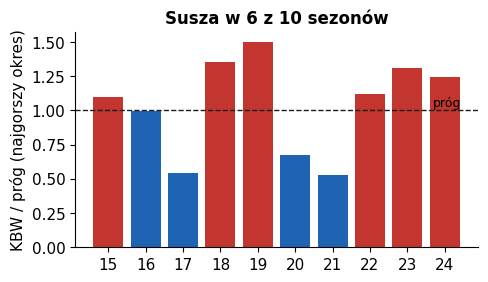

In [24]:
hist = out["historia"]["lata"]
for hh in hist:
    print(f"  {hh['y']}: {hh['crop']:18} {hh['tag']:9} · {hh['tip']}")
print(f"\nF5 = {out['historia']['F5']} z {out['historia']['n']} sezonów · {out['historia']['opis']}")

lata_h, ratio, kolory, etyk = [], [], [], []
for y in range(2015, 2025):
    c_ = _clms_rok(wcl, y)          # ta sama reguła co backend: uprawa z mapy tylko przy ≥ 50% pikseli
    uy = UPRAWY[c_["key"]] if c_ else u
    s = sezon_kbw(m, uy, kat, y)
    lata_h.append(str(y)[2:])
    if s.get("dostepny"):
        ratio.append(s["kbw"] / s["prog"]); kolory.append(CZER if s["kbw"] < s["prog"] else NIEB); etyk.append("")
    else:
        ratio.append(0); kolory.append(SZARY); etyk.append("bez\nprogu")
fig, ax = plt.subplots(figsize=(5.2, 2.8))
ax.bar(lata_h, ratio, color=kolory)
ax.axhline(1, color=TEKST, lw=1, ls="--"); ax.text(9.45, 1.03, "próg", fontsize=9, ha="right")
for i, e in enumerate(etyk):
    if e: ax.text(i, .05, e, ha="center", fontsize=7, color=SZARY)
ax.set_ylabel("KBW / próg (najgorszy okres)")
ax.set_title(f"Susza w {out['historia']['F5']} z {out['historia']['n']} sezonów")
zapisz(fig, "b4_historia")

## B5. F14–F15: opad i parowanie względem normy, upał

- **F14** = opad z 60 dni przed D / średnia z tych samych dni w 30 latach → przyczyna **C1 „mało deszczu”** (< 70% normy).
- **F15** = liczba dni z Tmax > 30°C w 30 dniach przed D oraz ET0 60 dni / norma → przyczyna **C2 „upał / duże parowanie”**.

**Co daje:** rozdzielenie przyczyn **pogodowych** (na które rolnik nie ma wpływu) od **stałych cech działki** (na które działają zalecenia).

opad 60 dni 147 mm vs norma 133 mm (111%) · ET0 245 vs 230 mm (106%) · dni > 30°C: 1
zgodne z backendem: True


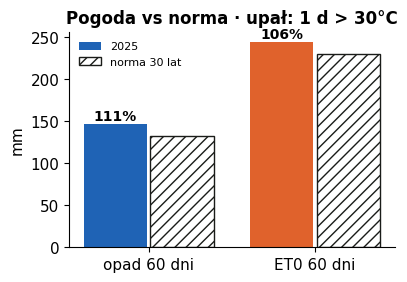

In [25]:
a60, b60 = D - timedelta(days=59), D
P60, E60 = m.suma(m.P, a60, b60), m.suma(m.ET0, a60, b60)
normP = [m.suma(m.P, _shift(a60, -k), _shift(b60, -k)) for k in range(1, 31)]
normE = [m.suma(m.ET0, _shift(a60, -k), _shift(b60, -k)) for k in range(1, 31)]
nP, nE = float(np.mean(normP)), float(np.mean(normE))
upal = int((m.TMAX[m.idx[D - timedelta(days=29)]: iD + 1] > 30).sum())
print(f"opad 60 dni {P60:.0f} mm vs norma {nP:.0f} mm ({100 * P60 / nP:.0f}%) · ET0 {E60:.0f} vs {nE:.0f} mm ({100 * E60 / nE:.0f}%) · dni > 30°C: {upal}")
print("zgodne z backendem:", round(P60, 1) == round(F["P60"], 1) and upal == F["upal"])
fig, ax = plt.subplots(figsize=(4.2, 2.8))
xx = np.arange(2)
ax.bar(xx - .2, [P60, E60], .38, color=[NIEB, POM], label="2025")
ax.bar(xx + .2, [nP, nE], .38, color="none", edgecolor=TEKST, hatch="///", label="norma 30 lat")
for i, (v, n) in enumerate([(P60, nP), (E60, nE)]):
    ax.text(i - .2, v + 4, f"{100 * v / n:.0f}%", ha="center", fontsize=10, fontweight="bold")
ax.set_xticks(xx, ["opad 60 dni", "ET0 60 dni"]); ax.set_ylabel("mm")
ax.legend(frameon=False, fontsize=8); ax.set_title(f"Pogoda vs norma · upał: {upal} d > 30°C")
zapisz(fig, "b5_norma")

## B6. F11: deszcz w najbliższych 7 dniach

Dla D = dziś: suma opadu z prognozy (A3). Dla daty archiwalnej (jak tu) nie istnieje prognoza wydana tego dnia,
więc bierzemy **średnią z 10 poprzednich lat dla tych samych 7 dni** (klimatologia).
**Co daje:** decyzja o nawadnianiu – dawka R7 = brak wody (Dr) **minus** deszcz, który i tak spadnie.

In [26]:
vals = [m.suma(m.P, _shift(D + timedelta(days=1), -k), _shift(D + timedelta(days=7), -k)) for k in range(1, 11)]
F11 = float(np.mean(vals))
print("opad 16–22.07 w latach 2015–2024:", [round(v) for v in vals])
print(f"F11 = {F11:.1f} mm · zgodne z backendem: {round(F11, 1) == round(F['F11'], 1)}")

opad 16–22.07 w latach 2015–2024: [20, 12, 7, 41, 30, 3, 75, 17, 1, 22]
F11 = 22.8 mm · zgodne z backendem: True


## B7. F7–F9: teren, spływ, zagłębienia, rów

- **F7 spadek** = gradient DEM (%), średni i 95. percentyl w działce, udział powierzchni > 3%.
- **F7b spływ**: kierunki D8 na DEM z wypełnionymi zagłębieniami (priority‑flood) → akumulacja → **komórka, przez którą odpływa
  najwięcej wody z działki** (tam pas buforowy R3); udział opadu, który spływa w ulewach > 10 mm z 10 lat (SCS‑CN, λ = 0,05).
- **F8 zagłębienia** = wypełniony DEM − DEM > 0,1 m → powierzchnia i objętość (kandydat na oczko wodne R2).
- **F9 rów** = najbliższy rów/kanał z BDOT10k, odległość od granicy (A10) → C5 i R1.

wysokość 80.7–89.6 m · spadek średni 3.0%, 95. percentyl 10.3% · > 3% na 25% działki
wypływ: {'lon': 17.761916434250654, 'lat': 53.04422278603269, 'udzial': 0.5333333333333333, 'w_zaglebienie': False}
zagłębienia: [{'pow_ha': 11.22004536363307, 'objetosc_m3': 128193.93570628505, 'udzial_w': 0.05343511450381679, 'lon': 17.757581192520377, 'lat': 53.04242889290292, 'w_dzialce': False}, {'pow_ha': 4.368109263704477, 'objetosc_m3': 35657.995078244945, 'udzial_w': 0.0196078431372549, 'lon': 17.758411532289873, 'lat': 53.046581173832266, 'w_dzialce': False}, {'pow_ha': 3.0833712449678665, 'objetosc_m3': 15701.237460123299, 'udzial_w': 0.16666666666666666, 'lon': 17.764196526843243, 'lat': 53.04342803294626, 'w_dzialce': False}]
ulew > 10 mm w 2015–2025: 135 · spływa F7b = 1.9% ich opadu (CN 67)


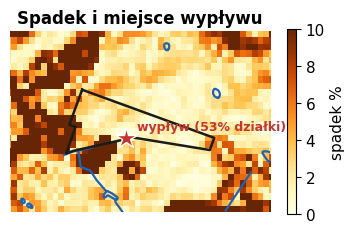

In [27]:
ter = terrain.analiza_terenu(wdem.dane, rings)
print(f"wysokość {ter['wys_min']:.1f}–{ter['wys_max']:.1f} m · spadek średni {ter['spadek_sr']:.1f}%, 95. percentyl {ter['spadek_max']:.1f}% · "
      f"> 3% na {100 * ter['udzial_pow_3']:.0f}% działki")
print("wypływ:", ter["wyplyw"])
print("zagłębienia:", [{k: v for k, v in z.items() if k != 'obrys'} for z in ter["zaglebienia"]] or "brak")
i10 = m.idx[date(2015, 1, 1)]
P10 = m.P[i10:iD + 1]; ulewy = P10[P10 > 10]
F7b = float(sum(odplyw(float(x), s_cn(CN)) for x in ulewy) / ulewy.sum())
print(f"ulew > 10 mm w 2015–2025: {len(ulewy)} · spływa F7b = {100 * F7b:.1f}% ich opadu (CN {CN})")

zz = np.where(np.isnan(Z), np.nanmean(Z), Z)
dx = abs(TR.a) * 111320 * math.cos(math.radians(LAT0)); dy = abs(TR.e) * 110574
gy, gx = np.gradient(zz, dy, dx)
fig, ax = plt.subplots(figsize=(4.2, 3))
im = ax.imshow(100 * np.hypot(gx, gy), extent=EXT, cmap="YlOrBr", vmin=0, vmax=10)
for l in hyd["linie"]:
    c = np.array(l["c"]); ax.plot(c[:, 0], c[:, 1], color=NIEB, lw=1.6)
obrys(ax)
wy = ter["wyplyw"]
if wy:
    ax.plot(wy["lon"], wy["lat"], "*", ms=16, color=CZER, mec="white")
    ax.annotate(f"wypływ ({100 * wy['udzial']:.0f}% działki)", (wy["lon"], wy["lat"]), xytext=(8, 6), textcoords="offset points",
                color=CZER, fontsize=9, fontweight="bold")
x0, y0, x1, y1 = geo.bbox(rings); ax.set_xlim(x0 - .004, x1 + .004); ax.set_ylim(y0 - .0025, y1 + .0025)
plt.colorbar(im, ax=ax, shrink=.8, label="spadek %")
ax.set_title("Spadek i miejsce wypływu"); bez_osi(ax)
zapisz(fig, "b7_teren")

## B8. F10: anomalia NDMI – gdzie rośliny są suchsze niż zwykle

**Wzór:** dla każdego piksela 20 m: **z = (NDMI_teraz − średnia z lat odniesienia) / odchylenie** (te same tygodnie, ten sam sensor).
**Lata odniesienia** to tylko sezony, w których rosła **ta sama grupa łanu** (zboża / kukurydza / rzepak / okopowe / użytki zielone)
i w tym dniu roku na polu były rośliny (L1 w `TODO_LUKI.md`). Przy mniej niż 3 takich latach satelity nie oceniamy.
Piksele z z < −1 → „najsuchsza strefa” (F10); mediana z w działce (F10b) to trzeci sygnał pewności.
**Co daje:** **GDZIE** w działce kierować wodę (R7/R8) – zamiast „podlej całe 10 ha” → „podlej tę strefę”.

[Sentinel‑2 L2A – Sentinel Hub (CDSE)] OK · 6 ms
czyste zdjęcia z lat: [2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024]
z nich ta sama grupa łanu (kukurydza): [2021, 2022, 2023]; pozostałe lata – inna uprawa albo nie wiemy, co rosło
scena 2025-07-15 · lata odniesienia [2021, 2022, 2023] · NDMI mediana 0.152 · z mediana -0.44 · suchsze niż zwykle (z < −1): 23% działki (2.32 ha)
zgodne z backendem: True


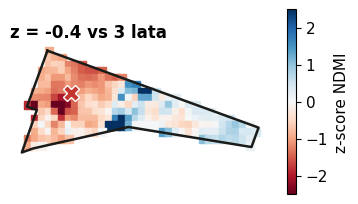

In [28]:
from app.analysis import lata_tej_samej_uprawy
from app.crops import grupa
wraw = await cdse.ndmi_anomalia_sh(client, rings, D, okno_sat)     # scena docelowa + te same dni z poprzednich lat
if not wraw.ok:
    wraw = await satellite.ndmi_anomalia(client, rings, D, okno_sat)
pokaz(wraw)
lata_zdjec = sorted(y for y, _ in wraw.dane["refs"])
dzien_sceny = date.fromisoformat(wraw.dane["meta"]["data"])
lata_ok = lata_tej_samej_uprawy(lata_zdjec, u, dzien_sceny, uprawa_roku)
print(f"czyste zdjęcia z lat: {lata_zdjec}")
print(f"z nich ta sama grupa łanu ({grupa(u)}): {sorted(lata_ok)}; pozostałe lata – inna uprawa albo nie wiemy, co rosło")
wsat = satellite.anomalia(wraw, lata_ok)
if not wsat.ok:
    print("satelity nie oceniamy:", wsat.powod)
else:
    sat = wsat.dane
    print(f"scena {sat['data']} · lata odniesienia {sat['lata_ref']} · NDMI mediana {sat['ndmi_med']:.3f} · z mediana {sat['z_med']:+.2f} · "
          f"suchsze niż zwykle (z < −1): {100 * sat['sucho_udzial']:.0f}% działki ({sat['sucho_ha']:.2f} ha)")
    print("zgodne z backendem:", sat["lata_ref"] == out["sucho"]["lata"] and abs(sat["z_med"] - out["sucho"]["z_med"]) < 1e-9
          and abs(sat["sucho_ha"] - out["sucho"]["sucho_ha"]) < 1e-9)
    pk = np.array(sat["piksele"])
    fig, ax = plt.subplots(figsize=(4.2, 3))
    sc = ax.scatter(pk[:, 0], pk[:, 1], c=pk[:, 2], cmap="RdBu", norm=TwoSlopeNorm(0, -2.5, 2.5), marker="s", s=34)
    obrys(ax); plt.colorbar(sc, ax=ax, shrink=.8, label="z‑score NDMI")
    if sat["sucho_srodek"]:
        ax.plot(*sat["sucho_srodek"], "X", ms=11, color=CZER, mec="white")
    ax.set_title(f"z = {sat['z_med']:+.1f} vs {len(sat['lata_ref'])} lata", loc="left"); bez_osi(ax)
    zapisz(fig, "b8_ndmi_z")

## B9. F17–F21: scenariusze – co czeka działkę (Ensemble Streamflow Prediction)

Nie znamy pogody na kolejne tygodnie, ale znamy 10 poprzednich sezonów w tym miejscu. Puszczamy **ten sam bilans FAO‑56 (B3)
od dzisiejszego zapasu** przez pogodę każdego z tych lat (te same dni roku) → **10 możliwych przebiegów**.

- **F18 ryzyko** = w ilu z 10 przebiegów zapas spadnie poniżej progu stresu w danym tygodniu,
- **F19 brak wody** = Σ(ETc − ETa) w oknie wrażliwości → mediana i 80. percentyl (typowy / suchy sezon),
- **F20/F21 efekt działań** = te same 10 przebiegów z parametrem zmienionym przez działanie (np. dawka 20 mm dziś, mniejsze parowanie pod mulczem).

**Co daje:** status w nagłówku raportu („Susza / Zagrożenie / Spokojnie”) i „Co zyskasz” na każdej karcie zalecenia.

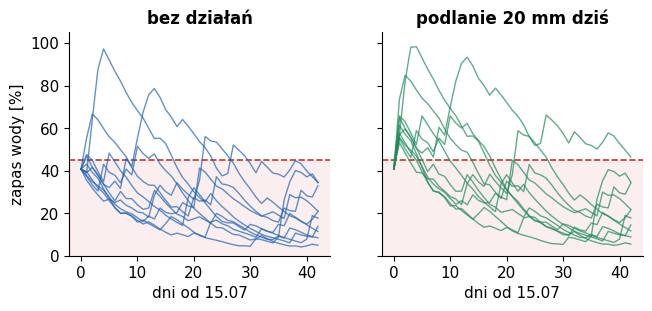

tydzień:             ['do 22.07', 'do 29.07', 'do 05.08', 'do 12.08', 'do 19.08', 'do 26.08']
ryzyko bez działań:  [9, 8, 9, 10, 10, 10]  (backend: [9, 8, 9, 10, 10, 10] )
ryzyko z 20 mm dziś:   [4, 6, 9, 8, 9, 9]
ryzyko z całym planem (backend, wszystkie zalecenia naraz): [4, 6, 9, 8, 9, 9]
stres w 14 dni: 10/10 → 6/10 · brak wody w oknie wrażliwym: mediana 82 mm, suchy rok (p80) 113 mm


In [29]:
koniec, cols, _ = horyzont(D)
dni_h = [D + timedelta(days=k) for k in range(1, (koniec - D).days + 1)]
dawka = min(Dr - F11, C.MAX_DAWKA[kat])
fig, axs = plt.subplots(1, 2, figsize=(7.4, 2.9), sharey=True)
for ax, plan, tyt in ((axs[0], None, "bez działań"), (axs[1], Plan(dawka_teraz=dawka), f"podlanie {dawka:.0f} mm dziś")):
    ax.axhspan(0, 100 * F4p, color=CZER, alpha=.08)
    ax.axhline(100 * F4p, color=CZER, ls="--", lw=1.2)
    for k in range(1, 11):
        src = [_shift(x, -k) for x in dni_h]
        P = np.array([m.P[m.idx[s]] for s in src]); E = np.array([m.ET0[m.idx[s]] for s in src])
        r = bilans(P, E, dni_h, u, TAW, CN, Dr, plan)
        ax.plot([0] + list(range(1, len(dni_h) + 1)), [100 * F4] + list(100 * (1 - r["Dr"] / TAW)),
                color=NIEB if plan is None else ZIEL, lw=1, alpha=.7)
    ax.set_title(tyt); ax.set_xlabel("dni od 15.07")
axs[0].set_ylabel("zapas wody [%]"); axs[0].set_ylim(0, 105)
zapisz(fig, "b9_scenariusze")

base = scenariusze(m, u, TAW, CN, D, Dr, None, 10)
s7 = scenariusze(m, u, TAW, CN, D, Dr, Plan(dawka_teraz=dawka), 10)
print("tydzień:            ", base["kolumny"])
print("ryzyko bez działań: ", base["ryzyko"], " (backend:", out["ryzyko"]["bez"], ")")
print(f"ryzyko z {dawka:.0f} mm dziś:  ", s7["ryzyko"])
print("ryzyko z całym planem (backend, wszystkie zalecenia naraz):", out["ryzyko"]["plan"])
print(f"stres w 14 dni: {round(base['f18_14'] * 10)}/10 → {round(s7['f18_14'] * 10)}/10 · brak wody w oknie wrażliwym: "
      f"mediana {base['brak_med']:.0f} mm, suchy rok (p80) {base['brak_p80']:.0f} mm")

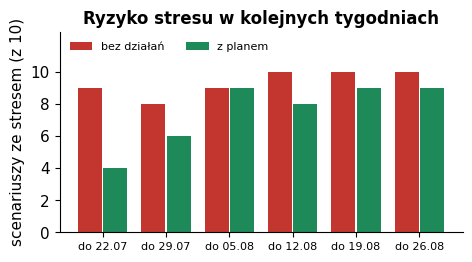

In [30]:
fig, ax = plt.subplots(figsize=(5.2, 2.6))
xx = np.arange(len(out["ryzyko"]["kolumny"]))
ax.bar(xx - .2, out["ryzyko"]["bez"], .38, color=CZER, label="bez działań")
ax.bar(xx + .2, out["ryzyko"]["plan"], .38, color=ZIEL, label="z planem")
ax.set_xticks(xx, out["ryzyko"]["kolumny"], fontsize=8); ax.set_ylim(0, 10.5); ax.set_ylabel("scenariuszy ze stresem (z 10)")
ax.set_ylim(0, 12.5); ax.set_yticks([0, 2, 4, 6, 8, 10])
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper left"); ax.set_title("Ryzyko stresu w kolejnych tygodniach")
zapisz(fig, "b9_ryzyko")

## B10. Diagnoza i reguły → raport

**Stan (5.1):** z F18 w 14 dni: ≥ 70% przebiegów → „Susza”, 30–69% → „Zagrożenie”, < 30% → „Spokojnie”.
**Pewność** = ile z 4 niezależnych sygnałów się zgadza: (KBW/opad), (bilans glebowy), (satelita), (EDO).
**Przyczyny C1–C6** dostają ocenę 0–3 z progów w `config.py`.
**Reguły R1–R9** to stałe warunki „jeśli… to…”; **czy** zalecenie się pojawi oraz **gdzie, kiedy i ile** – wynika wyłącznie z faktów powyżej.
Kolejność: retencja (R1–R4) → pole (R5–R6) → nawadnianie (R7–R8).

In [31]:
st = out["status"]
print(f"STAN: {st['label']} – {st['head']}\n  {st['sub']}")
print("  pewność:", st["pewnosc"], "·", ", ".join(f"{s['t']}: {'tak' if s['v'] else 'nie' if s['v'] is False else 'brak'}" for s in st["sygnaly"]))
print("\nPRZYCZYNY:")
for p in out["przyczyny"]:
    print(f"  {p['id']} [{p['score']}/3, {p['lvl']}, {p['ctl']}] {p['name']} – {p['ev']}")
print("\nZALECENIA:")
for a_ in out["akcje"]:
    print(f"  {a_['n']}. {a_['id']} {a_['title']}\n     gdzie: {a_['where']} · kiedy: {a_['when']}\n     bo: {a_['cause']} · zysk: {a_['gain']}")
print("\npilne:", out["pilne"])
print("\nCZEGO NIE SPRAWDZILIŚMY:", out["braki"])

STAN: Susza – Kukurydza już cierpi — zapas wody poniżej progu stresu
  Dziś w glebie 41% wody dostępnej (stres poniżej 45%). W 10 z 10 scenariuszy na najbliższe 2 tygodnie pojawi się stres. Kryterium suszy IUNG nie jest spełnione. W 6 z 10 ostatnich sezonów brakowało wody, najczęściej w czerwcu i lipcu.
  pewność: średnia · opady / próg IUNG: nie, woda w glebie (FAO‑56): tak, rośliny z satelity: nie, tło suszy EDO: nie

PRZYCZYNY:
  C3 [3/3, główna, da się zmienić] Lekka gleba — mały „zbiornik” na wodę – kategoria IUNG I – bardzo podatna (piaski) · woda dostępna w strefie korzeni ok. 110 mm · 71% piasku, 1,7% węgla (SoilGrids)
  C6 [2/3, duża, termin] Niedobór w krytycznej fazie – kukurydza: wiechowanie i kwitnienie (lipiec–sierpień)
  C5 [2/3, duża, da się zmienić] Rów odprowadza wodę – rów melioracyjny 3 m od granicy działki (BDOT10k)
  C4 [1/3, mała, da się zmienić] Woda spływa z pola – średni spadek 3%, na 25% działki ponad 3% · przy ulewach (> 10 mm) ok. 2% deszczu spływa (SCS‑CN)

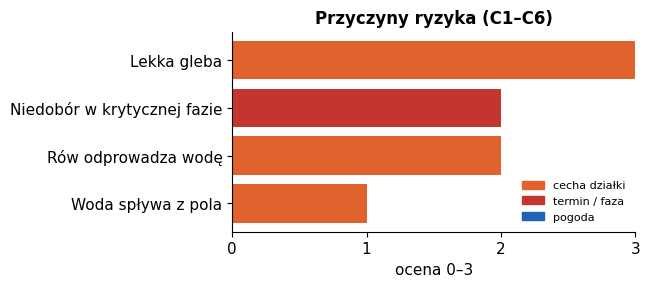

In [32]:
pr = out["przyczyny"][::-1]
fig, ax = plt.subplots(figsize=(5.2, 2.6))
ax.barh([p["name"].split("—")[0].strip() for p in pr], [p["score"] for p in pr],
        color=[NIEB if p["ctl"] == "pogoda" else POM if p["ctl"] == "da się zmienić" else CZER for p in pr])
ax.set_xlim(0, 3); ax.set_xticks([0, 1, 2, 3]); ax.set_xlabel("ocena 0–3")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=POM, label="cecha działki"), Patch(color=CZER, label="termin / faza"), Patch(color=NIEB, label="pogoda")],
          frameon=False, fontsize=8, loc="lower right")
ax.set_title("Przyczyny ryzyka (C1–C6)")
zapisz(fig, "b10_przyczyny")

---
# Część C – zalecenia: kiedy, dlaczego i gdzie

Każda reguła odpowiada na trzy pytania:
1. **Kiedy się uruchamia** – warunek na faktach z części B (nie ma zaleceń „na wszelki wypadek”).
2. **Dlaczego** – co mówi metoda (FAO‑56, NWRM, progi IUNG) i jakie liczby z tej działki to uzasadniają.
3. **Gdzie** – miejsce z danych: punkt rowu najbliżej granicy (BDOT10k), punkt wypływu wody (D8 na DEM),
   środek zagłębienia (wypełnianie DEM) albo najsuchsza strefa (z‑score NDMI). Działania na całą działkę nie mają miejsca –
   ich pinezka na mapie tylko oznacza kartę.

Komórka niżej liczy warunki jeszcze raz z faktów notebooka i porównuje listę uruchomionych reguł z `analizuj()`.

In [33]:
F5 = out["historia"]["F5"]
ryz_max = base["f18_max"]
najbl = hyd["najblizsze"]
rowy = [x for x in (najbl.get("SWRM_L"), najbl.get("SWKN_L")) if x]
F9 = min(rowy, key=lambda x: x["dist_m"]) if rowy else None
zagl = [z for z in ter["zaglebienia"] if z.get("udzial_w", 1.0 if z["w_dzialce"] else 0.0) >= 0.3]
F8 = max(zagl, key=lambda z: z["objetosc_m3"]) if zagl else None
wy = ter["wyplyw"]
sr = ter["spadek_sr"]
sc4 = max(3 if sr > 8 else 2 if sr > 5 else 1 if sr > 3 else 0, 1 if F7b > 0.10 else 0)
sc3 = max(3 if kat == 1 else 2 if kat == 2 else 0, 2 if TAW < C.C3_TAW else 0)
organiczna = wi.dane["udzial_organiczne"] >= 0.3
okno_teraz = w_oknie(u, D) and faza != "poza wegetacją"
f18d = base.get("f18d")
brak_mm = Dr - F11
potrzeba = bool(kbw.get("susza")) or F5 >= 3 or ryz_max >= C.PROG_ZAGROZENIE

print(f"BRAMKA retencji: susza IUNG teraz = {bool(kbw.get('susza'))} · susza w {F5}/10 sezonów (≥ 3?) · "
      f"ryzyko w scenariuszach {100 * ryz_max:.0f}% (≥ 30%?) → potrzeba = {potrzeba}\n")
R7 = (F4 < F4p or (f18d is not None and f18d <= 7)) and brak_mm > C.R7_MIN_BRAK and okno_teraz
reguly = [
    ("R1", F9 is not None and F9["dist_m"] <= 100 and potrzeba,
     f"rów ≤ 100 m i potrzeba: {F9['typ']} {F9['dist_m']:.0f} m" if F9 else "brak rowu w BDOT10k"),
    ("R2", F8 is not None and (F8["objetosc_m3"] >= 100 or F8["pow_ha"] >= 0.05) and potrzeba,
     "zagłębienia przy działce: " + (", ".join(f"{z['objetosc_m3']:,.0f} m³ / {100 * z['udzial_w']:.0f}% w działce".replace(",", " ")
                                             for z in ter["zaglebienia"]) or "brak") + " (potrzeba ≥ 30% w działce)"),
    ("R3", sc4 >= 1 and wy is not None, f"C4 = {sc4} (spadek śr. {sr:.2f}%, spływ {100 * F7b:.1f}%), wypływ {100 * wy['udzial']:.0f}% działki" if wy else f"C4 = {sc4}, brak wypływu"),
    ("R4", organiczna, f"gleba organiczna na {100 * wi.dane['udzial_organiczne']:.0f}% punktów (≥ 30%?)"),
    ("R5", sc3 >= 2 or ryz_max >= C.PROG_ZAGROZENIE or sg["soc"] < 1.5, f"C3 = {sc3} (≥ 2?), ryzyko {100 * ryz_max:.0f}%, SOC {sg['soc']:.1f}% (< 1,5?)"),
    ("R6", sc4 >= 2, f"C4 = {sc4} (≥ 2?)"),
    ("R7", R7, f"zapas {100 * F4:.0f}% < próg {100 * F4p:.0f}%, brak {Dr:.0f} − deszcz {F11:.0f} = {brak_mm:.0f} mm (> 10?), okno wrażliwe: {okno_teraz}"),
    ("R7-", (not R7) and (F4 >= F4p or F11 >= Dr - RAW), "tylko gdy nie ma R7: zapas ≥ próg albo deszcz pokryje brak"),
    ("R8", (not R7) and ryz_max >= C.PROG_ZAGROZENIE, "tylko gdy nie ma R7: ryzyko w scenariuszach ≥ 30%"),
]
alt = []
for k2, u2 in UPRAWY.items():
    if k2 == u.key or not u2.wiersz_iung:
        continue
    sez = [sezon_kbw(m, u2, kat, y) for y in range(2015, 2025)]
    alt.append((sum(1 for s in sez if s.get("dostepny") and s["stopien"] != "brak"), sum(1 for s in sez if s.get("dostepny")), u2.nazwa))
alt.sort()
reguly.append(("R9", F5 >= 6 and bool(u.wiersz_iung) and bool(alt) and alt[0][0] <= 3,
               f"susza {F5}/10 (≥ 6?); najlepsza inna uprawa: {alt[0][2].lower()} {alt[0][0]}/10" if alt else "brak"))
for rid, ok, why in reguly:
    print(f"  {'✔' if ok else '·'} {rid:4} {why}")
moje = {rid for rid, ok, _ in reguly if ok}
print("\nzgodne z backendem:", moje == {a_["id"] for a_ in out["akcje"]}, "·", sorted(moje))

BRAMKA retencji: susza IUNG teraz = False · susza w 6/10 sezonów (≥ 3?) · ryzyko w scenariuszach 100% (≥ 30%?) → potrzeba = True

  ✔ R1   rów ≤ 100 m i potrzeba: rów melioracyjny 3 m
  · R2   zagłębienia przy działce: 128 194 m³ / 5% w działce, 35 658 m³ / 2% w działce, 15 701 m³ / 17% w działce (potrzeba ≥ 30% w działce)
  ✔ R3   C4 = 1 (spadek śr. 3.01%, spływ 1.9%), wypływ 53% działki
  · R4   gleba organiczna na 0% punktów (≥ 30%?)
  ✔ R5   C3 = 3 (≥ 2?), ryzyko 100%, SOC 1.7% (< 1,5?)
  · R6   C4 = 1 (≥ 2?)
  ✔ R7   zapas 41% < próg 45%, brak 65 − deszcz 23 = 42 mm (> 10?), okno wrażliwe: True
  · R7-  tylko gdy nie ma R7: zapas ≥ próg albo deszcz pokryje brak
  · R8   tylko gdy nie ma R7: ryzyko w scenariuszach ≥ 30%
  ✔ R9   susza 6/10 (≥ 6?); najlepsza inna uprawa: burak cukrowy 0/10

zgodne z backendem: True · ['R1', 'R3', 'R5', 'R7', 'R9']


### R9 – sprawdzenie: czy „0/10 sezonów z suszą” to brak suszy?

R9 porównuje liczbę sezonów z przekroczonym progiem IUNG dla innych upraw na tej samej glebie i pogodzie.
Kolumna „sezonów z progiem” pokazuje, w ilu z 10 sezonów tabela IUNG w ogóle ma próg dla tej uprawy i kategorii gleby.

In [34]:
for n_s, n_ok, nazwa in alt:
    print(f"  {nazwa:28} susza {n_s}/10 · sezonów z progiem IUNG: {n_ok}/10{'   ← 0/10 to brak danych, nie brak suszy' if n_ok == 0 else ''}")

  Burak cukrowy                susza 0/10 · sezonów z progiem IUNG: 0/10   ← 0/10 to brak danych, nie brak suszy
  Inna uprawa                  susza 3/10 · sezonów z progiem IUNG: 10/10
  Ziemniak                     susza 3/10 · sezonów z progiem IUNG: 10/10
  Rzepak                       susza 7/10 · sezonów z progiem IUNG: 10/10
  Zboża ozime                  susza 7/10 · sezonów z progiem IUNG: 10/10
  Zboża jare                   susza 8/10 · sezonów z progiem IUNG: 10/10


### Gdzie: miejsca zaleceń na mapie

Te same punkty, które raport pokazuje jako pinezki: rów (najbliższy punkt rowu do granicy, BDOT10k), wypływ wody (komórka na granicy,
przez którą odpływa najwięcej wody z działki, D8), najsuchsza strefa (piksele z z < −1, punkt = średnia ich położeń).

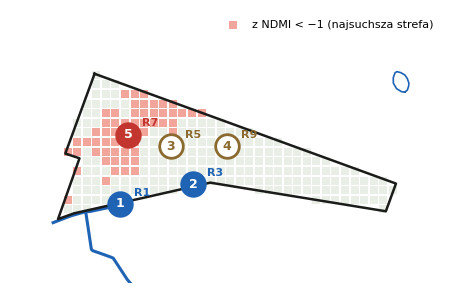

  1. R1  rów melioracyjny, 3 m od granicy (punkt na mapie)  →  [17.759612, 53.043859]
  2. R3  granica działki w miejscu wypływu wody, pas 6–10 m (punkt na mapie)  →  [17.761916, 53.044223]
  3. R5  cała działka  →  [17.761204, 53.044935]
  4. R9  cała działka  →  [17.762963, 53.044935]
  5. R7  najsuchsza część działki, ok. 2,3 ha (satelita 15.07)  →  [17.759875, 53.045158]


In [35]:
fig, ax = plt.subplots(figsize=(5.6, 3.6))
if wsat.ok:
    pk = np.array(sat["piksele"])
    suche = pk[:, 2] < satellite.Z_SUCHO
    ax.scatter(pk[~suche, 0], pk[~suche, 1], c="#e9eee6", marker="s", s=30, lw=0)
    ax.scatter(pk[suche, 0], pk[suche, 1], c="#f2a59b", marker="s", s=30, lw=0, label="z NDMI < −1 (najsuchsza strefa)")
for l in hyd["linie"]:
    c = np.array(l["c"]); ax.plot(c[:, 0], c[:, 1], color=NIEB, lw=2.2 if l["typ"] == "SWRM_L" else 1.2)
obrys(ax)
if wy:
    ax.plot(wy["lon"], wy["lat"], "*", ms=15, color=TEKST, mec="white", zorder=4)
KOL_A = {"ret": NIEB, "agro": "#8a6a2f", "irr": CZER}
for a_ in out["akcje"]:
    x_, y_ = a_["punkt"]
    calosc = a_["where"].startswith("cała")
    ax.plot(x_, y_, "o", ms=17, color="white" if calosc else KOL_A[a_["cat"]], mec=KOL_A[a_["cat"]], mew=2, zorder=5)
    ax.text(x_, y_, str(a_["n"]), ha="center", va="center", fontsize=9, fontweight="bold",
            color=KOL_A[a_["cat"]] if calosc else "white", zorder=6)
    ax.annotate(a_["id"], (x_, y_), xytext=(10, 6), textcoords="offset points", fontsize=8, color=KOL_A[a_["cat"]], fontweight="bold")
x0, y0, x1, y1 = geo.bbox(rings); ax.set_xlim(x0 - .0015, x1 + .0015); ax.set_ylim(y0 - .0012, y1 + .0012)
bez_osi(ax)
ax.legend(frameon=False, fontsize=8, loc="upper right")
zapisz(fig, "c1_miejsca")
for a_ in out["akcje"]:
    print(f"  {a_['n']}. {a_['id']:3} {a_['where']}  →  {a_['punkt']}")

## Podsumowanie źródeł tej analizy

In [36]:
for z in out["zrodla"]:
    print(f"  {'OK ' if z['ok'] else '-- '} {z['zrodlo']:42} {z['czas_ms']:6d} ms {'(cache)' if z['z_cache'] else ''} {z['powod'] or ''}")
await client.aclose()

  OK  ULDK GUGiK                                      0 ms (cache) 
  OK  Open‑Meteo (ERA5‑Land)                          6 ms (cache) 
  OK  IUNG‑PIB – kategorie gleb                     189 ms  
  OK  ARiMR – deklaracje upraw 2025                   0 ms (cache) 
  --  ARiMR – deklaracje upraw 2024                   0 ms  brak usługi WFS dla 2024 (2020–2024: shapefile do przetworzenia – T3.9)
  OK  Copernicus DEM 30 m                          1181 ms  
  OK  BDOT10k – hydrografia                         622 ms  
  OK  EDO – Combined Drought Indicator                0 ms (cache) 
  OK  ISRIC SoilGrids 250 m                         120 ms (cache) 
  OK  CLMS Crop Types 2017–2024 (CDSE)                0 ms (cache) 
  OK  MPHP10k – zlewnie (Wody Polskie)               58 ms (cache) 
  OK  Sentinel‑2 L2A – Sentinel Hub (CDSE)            5 ms  
